# How many distinct chemotypes hit BRD4

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-opus-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.9, commit [`5ea8c6253a4c`](https://github.com/pwrose/mcp-bindingdb/commit/5ea8c6253a4c012b3f3982669393dcdf831fca79)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-23T08:25:17Z
- **Contents:** 2 exchanges · 4 tool calls · 1 figure

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/4.6-ligand-clustering-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 4.6-ligand-clustering-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 4.6-ligand-clustering-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/4.6-ligand-clustering-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 4.6-ligand-clustering-notebook-rerun.ipynb 4.6-ligand-clustering-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/pwrose/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 5ea8c6253a4c012b3f3982669393dcdf831fca79
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.9 (commit 5ea8c6253a4c)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

How many distinct chemical series have been published against BRD4 with an IC50 under 100 nM? Show me the biggest ones with their most potent compound.

In [ ]:
# Call 1 · search_targets · ran 2026-11-23 08:25:16 UTC
await replay.call(1, 'search_targets', {'query': 'BRD4', 'organism': 'Homo sapiens', 'limit': 6},
                  sha256='0d8dc44b9f3442fba16037f4110e60a5d8e9826555f54a41911fc7a7e9418697')

**Call 1** · `search_targets` · recorded result · sha256 `0d8dc44b9f34…`

_6 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 6885 | Bromodomain-containing protein 4 | O60885 | O60885 | Homo sapiens | Protein | 13085 | 8562 | BRD4 |
| polymer | 506 | Bromodomain-containing protein 4 [42-168] | O60885 | O60885[42-168] | Homo sapiens | Enzyme Catalytic Domain | 1541 | 1142 | BRD4 |
| polymer | 539 | Bromodomain-containing protein 4 [342-460] | O60885 | O60885[342-460] | Homo sapiens | Enzyme Catalytic Domain | 1473 | 809 | BRD4 |
| polymer | 383 | Bromodomain-containing protein 4 [75-147] | O60885 | O60885[75-147] | Homo sapiens |  | 968 | 825 | BRD4 |
| polymer | 1168 | Bromodomain-containing protein 4 [58-164] | O60885 | O60885[58-164] | Homo sapiens | Enzyme Catalytic Domain | 807 | 792 | BRD4 |
| polymer | 538 | Bromodomain-containing protein 4 [49-170] | O60885 | O60885[49-170] | Homo sapiens | Enzyme Catalytic Domain | 700 | 671 | BRD4 |


In [ ]:
# Call 2 · cluster_ligands · ran 2026-11-23 08:25:17 UTC
arguments = {
    'uniprot': 'O60885',
    'include_variants': True,
    'max_value_nm': 100,
    'max_compounds': 5000,
    'limit': 10,
    'members_per_cluster': 50,
}
await replay.call(2, 'cluster_ligands', arguments,
                  sha256='fe06ba99bfc93094c8b3e6b46b2afa4ef4995b0f4fe077856a4ba9302953597c')

**Call 2** · `cluster_ligands` · recorded result · sha256 `fe06ba99bfc9…`

```json
{
  "affinity_type": "IC50",
  "n_compounds": 2814,
  "n_clusters": 826,
  "n_singletons": 387,
  "min_similarity": 0.7,
  "note": "Clustered at Tanimoto >= 0.7 on Morgan fingerprints (radius 2, 2048 bits) of each compound's largest fragment; a lower min_similarity gives fewer, broader clusters. 387 of the 826 clusters hold a single compound."
}
```

_10 rows, truncated at the limit_

| cluster | n_compounds | centroid_monomerid | centroid_name | centroid_p_affinity | centroid_value_nm | centroid_scaffold_smiles | best_monomerid | best_compound_name | best_p_affinity | best_value_nm | median_p_affinity | member_monomerids | centroid_smiles |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 76 | 502380 | N-[4-(7- methoxy-1- methyl- [1,2,4]tri- azolo[4,3- a]quinoxaline- 4-ylamino)- butyl]-3- methyl- butyramide | 7.77 | 17 | c1ccc2c(c1)ncc1nncn12 | 502377 | N-[4-(7- methoxy-1- methyl- [1,2,4]tri- azolo[4,3- a]quinoxaline- 4-ylamino)- butyl]- isobutyramide | 9.4 | 0.4 | 7.62 | 502377, 502466, 502392, 502360, 502393, 502623, 502173, 502177, 502361, 502396, 502401, 502537, 502379, 502436, 502676, 502677, 502384, 502613, 502678, 502448, 502565, 502619, 502376, 502415, 502383, 502394, 502395, 502519, 502380, 502375, 502404, 502425, 502154, 502280, 502399, 502438, 502385, 502430, 502313, 502391, 502529, 502207, 502275, 502423, 502645, 502381, 502618, 502352, 502625, 502390 | COc1ccc2c(c1)nc(NCCCCNC(=O)CC(C)C)c1nnc(C)n21 |
| 2 | 56 | 502459 | {4-[7-(2- methoxy- ethoxy)-1- methyl- [1,2,4]tri- azolo[4,3- a]quinoxaline- 4-ylamino]- butyl}- isobutyramide | 7.36 | 44 | c1ccc2c(c1)ncc1nncn12 | 502479 | (S)-(1-{4-[7- (2-methoxy- ethoxy)-1- methyl- [1,2,4]tri- azolo[4,3- a]quinoxaline- 4-ylamino]- butylcarbamo- | 9 | 1 | 7.85 | 502479, 502480, 502481, 502494, 502455, 502471, 502501, 502475, 502502, 502449, 502450, 502465, 502473, 502470, 502454, 502477, 502488, 502474, 502491, 502484, 502482, 502492, 502463, 502490, 502452, 502453, 502461, 502464, 502487, 502485, 502446, 502495, 502462, 502506, 502507, 502483, 502493, 502456, 502458, 502472, 502504, 502503, 502505, 502478, 502476, 502460, 502467, 502459, 502496, 502468 | COCCOc1ccc2c(c1)nc(NCCCCNC(=O)C(C)C)c1nnc(C)n21 |
| 3 | 54 | 50273482 | CHEMBL4127310 | 7 | 100 | O=C(CC1N=C(c2ccccc2)c2ccsc2-n2cnnc21)Nc1ccccc1 | 50623611 | CHEMBL5424952 | 10 | 0.1 | 7.96 | 50623611, 50623615, 50623605, 50623610, 50623602, 50623613, 50623612, 552060, 552046, 552042, 552043, 552047, 552048, 552034, 552056, 552059, 50092312, 552031, 552051, 552061, 552065, 552030, 552038, 552044, 552049, 552063, 552066, 50569836, 552045, 552064, 552033, 552040, 552032, 552053, 552062, 552036, 552052, 474460, 562619, 474458, 562599, 552050, 474457, 562570, 474459, 562610, 50624327, 50587649, 50643287, 50527588 | Cc1sc-2c(c1C)C(=NC(CC(=O)Nc1ccc(O)cc1)c1nnc(C)n-21)c1ccc(Cl)cc1 \|c:8\| |
| 4 | 48 | 502192 | US11028090, Example 57 | 7.7 | 20 | c1ccc2c(c1)ncc1nncn12 | 502217 | N-[4-(7,8- dimethoxy-1- methyl-[1,2,4] triazolo[4,3-a] quinoxaline-4- ylamino)-butyl]- 2-(S)-hydroxy- 3-methyl- butyramide | 8.7 | 2 | 7.46 | 502217, 502288, 502196, 502194, 502197, 502216, 502200, 502229, 502293, 502204, 502222, 502201, 502192, 502198, 502212, 502205, 502199, 502210, 502277, 502221, 502208, 502214, 502193, 502599, 502241, 502228, 502202, 502209, 502185, 502203, 502223, 502191, 502248, 502195, 502443, 502667, 502544, 502605, 502224, 502244, 502350, 502601, 502180, 502312, 502364, 502150, 502648, 502176 | COc1cc2nc(NCCCCNC(=O)OC(C)(C)C)c3nnc(C)n3c2cc1OC |
| 5 | 31 | 502158 | N-[4-(1- methyl- [1,2,4]tria zolo[4,3- a]quinoxali ne-4- ylamino)- butyl]- benzamide | 7.24 | 58 | O=C(NCCCCNc1nc2ccccc2n2cnnc12)c1ccccc1 | 502157 | 2-(S)- hydroxy-N- [4-(1- methyl- [1,2,4] triazolo [4,3-a] quinoxaline- 4-ylamino)- butyl]-3- | 8.3 | 5 | 7.35 | 502157, 502301, 502162, 502151, 502174, 502358, 502153, 502165, 502188, 502366, 502156, 502183, 502161, 502166, 502163, 502609, 502253, 502371, 502164, 502355, 502170, 502611, 502158, 502159, 502160, 502167, 502316, 502271, 502168, 502665, 502602 | Cc1nnc2c(NCCCCNC(=O)c3ccccc3)nc3ccccc3n12 |
| 6 | 30 | 480577 | 3-cyclopropyl-1-(3- (difluoromethyl)-2-(1  methyl-1H-pyrazol-3- yl)quinolin-5-yl)-5,7- dimethyl-7,8- dihydroimidazo[1,5-a]  pyrazin-6(5H)-one | 8.7 | 2 | O=C1Cn2c(C3CC3)nc(-c3cccc4nc(-c5cn[nH]c5)ccc34)c2CN1 | 480572 | 5-(3-cyclopropyl-5,7- dimethyl-6-oxo-5,6,7,8- tetrahydroimidazo[1,5-a] pyrazin-1-yl)-2-(1- methyl-1H-pyrazol-4- yl)quinoline-3-carbonitrile | 9 | 1 | 7.83 | 480572, 480632, 480542, 480552, 480562, 480577, 480636, 480643, 480492, 480578, 480592, 480586, 480538, 480537, 480587, 480583, 480541, 480640, 480595, 480536, 480597, 480535, 480596, 480601, 480543, 480598, 480581, 480534, 480540, 480539 | CC1C(=O)N(C)Cc2c(nc(C3CC3)n12)-c1cccc2nc(-c3cnn(C)c3)c(cc12)C(F)F |
| 7 | 28 | 50624429 | CHEMBL5416135 | 7.17 | 67 | O=C1CN(C2CCCC2)c2cc(-c3nc(C(=O)N4CCN(C(=O)c5nc(-c6ccc7c(c6)N(C6CCCC6)CC(=O)N7)n(-c6ccccc6)n5)CC4)nn3-c3ccccc3)ccc2N1 | 50530517 | CHEMBL4550548 | 8.39 | 4.06 | 8.16 | 50530517, 50530512, 50530513, 50530516, 50530502, 50530521, 50530511, 510747, 50530520, 50530522, 50530501, 50624426, 50530514, 50530518, 50530500, 50530503, 50530510, 510739, 50530525, 50530509, 510730, 510759, 510758, 510753, 510756, 50530515, 50624427, 50624429 | C[C@H]1N(C2CCCC2)c2cc(ccc2N(C)C1=O)-c1nc(nn1-c1ccc(C)cc1)C(=O)N1CCN(CC1)C(=O)c1nc(-c2ccc3N(C)C(=O)[C@H](C)N(C4CCCC4)c3c2)n(n1)-c1ccc(C)cc1 \|r\| |
| 8 | 27 | 50604624 | CHEMBL5206088 | 9.1 | 0.79 | O=c1[nH]cc(-c2ccccc2Oc2ccccc2)c2oc(-c3cnc(C4CCCC4)[nH]3)cc12 | 50604627 | CHEMBL5192071 | 9.34 | 0.46 | 8.35 | 50604627, 50604623, 50604622, 50604620, 50604626, 50604621, 50604624, 50604625, 50655344, 50655350, 50655342, 50655348, 50655354, 50655341, 50655355, 50655356, 50655362, 50655343, 50655347, 50655345, 50655349, 50655363, 50655346, 50655357, 50655364, 50655365, 50655366 | Cc1cc(F)cc(C)c1Oc1ccc(C(C)(C)O)cc1-c1cn(C)c(=O)c2cc(-c3cnc(C4CCCC4)[nH]3)oc12 |
| 9 | 25 | 50604588 | CHEMBL5200542 | 9.25 | 0.56 | O=c1[nH]cc(-c2ccccc2Oc2ccccc2)c2oc(-c3ccccc3)cc12 | 50604593 | CHEMBL5171062 | 9.48 | 0.33 | 9.1 | 50604593, 50604589, 50604610, 50604602, 50604601, 50604611, 50604596, 50604588, 50604609, 50604594, 50604591, 50604597, 50604607, 50604590, 50604600, 50604592, 50604603, 50604595, 50604606, 50604587, 50604598, 50604605, 50604599, 50604608, 50604604 | CCS(=O)(=O)Nc1ccc(Oc2ccc(F)cc2F)c(c1)-c1cn(C)c(=O)c2cc(oc12)-c1cc(C)c(OCCO)c(C)c1 |
| 10 | 23 | 296947 | 2-[3-(Dimethyl-1H-1,2,3-triazol-5-yl)-5-[oxan-4-yl(phenyl)methyl]-5H-pyrido[3,2-b]indol-7-yl]propan-2-ol | 9.1 | 0.8 | c1ccc([C@H](C2CCOCC2)n2c3ccccc3c3ncc(-c4cnn[nH]4)cc32)cc1 | 445527 | 2-[7-(Dimethyl-1H-1,2,3-triazol-5-yl)-8-fluoro-5-[(S)-oxan-4-yl(phenyl)methyl]-5H-pyrido[3,2-b]indol-3-yl]propan-2-ol | 9.4 | 0.4 | 8.96 | 445527, 575853, 445524, 445515, 296947, 297236, 297070, 297163, 50566614, 296964, 297144, 297268, 50566610, 50594425, 296886, 297283, 297225, 50663072, 297312, 445528, 50594424, 297244, 50566609 | Cc1nnn(C)c1-c1cnc2c(c1)n([C@@H](C1CCOCC1)c1ccccc1)c1cc(ccc21)C(C)(C)O \|r\| |


**🧠 Assistant**

**826 chemotypes, and the ten biggest hold 398 of
2,814 compounds.**

Pooling every BRD4 construct (`include_variants`, since most BRD4 data sits on bromodomain constructs
rather than the full-length entry) gives 2,814 compounds with an exact IC50 of
100 nM or better. Clustering them at Tanimoto ≥ 0.7 splits them into
826 chemotypes, of which 387 are singletons — a long tail
of one-off compounds around a small number of heavily worked series.

| cluster | compounds | best IC50 | median p | centroid | centroid IC50 |
|---|---|---|---|---|---|
| 1 | 76 | 0.4 nM | 7.62 | BDBM502380 | 17.0 nM |
| 2 | 56 | 1.0 nM | 7.85 | BDBM502459 | 44.0 nM |
| 3 | 54 | 0.1 nM | 7.96 | BDBM50273482 | 100.0 nM |
| 4 | 48 | 2.0 nM | 7.46 | BDBM502192 | 20.0 nM |
| 5 | 31 | 5.0 nM | 7.35 | BDBM502158 | 58.0 nM |
| 6 | 30 | 1.0 nM | 7.83 | BDBM480577 | 2.0 nM |

- Clusters 1, 2, 4 and 5 (211
  compounds) are all **1-methyl-triazolo[4,3-a]quinoxalines** with an aminobutyl amide tail, separated by
  what sits on the benzo ring: 7-methoxy, 7-(2-methoxyethoxy), 7,8-dimethoxy, unsubstituted.
- Cluster 3 (54 compounds, best 0.1 nM) is the
  **triazolo-thienodiazepine** chemotype — the JQ1 family.
- Cluster 6 is a different scaffold again, a methyl-imidazopyrimidinone bearing a pyrazolyl-quinoline.
- The top six clusters cover 295 compounds, 10% of the set.

Potency does not track cluster size: cluster 3 reaches 0.1 nM and cluster 1, the
largest, 0.4 nM, while the highest median of the six belongs to cluster
3.

## Exchange 2

**👤 User**

Is that different from just grouping them by scaffold? And show me a representative of each of the top clusters.

In [ ]:
# Call 3 · run_sql · ran 2026-11-23 08:25:17 UTC
sql = """
SELECT count(DISTINCT cp.scaffold) AS scaffolds, count(DISTINCT a.monomerid) AS compounds FROM activity a JOIN compound c USING (monomerid) JOIN compound_property cp USING (monomerid) WHERE a.uniprot = 'O60885' AND a.affinity_type = 'IC50' AND a.relation = '=' AND a.unit = 'nM' AND a.p_affinity IS NOT NULL AND a.value <= 100 AND c.smiles IS NOT NULL
"""
await replay.call(3, 'run_sql', {'sql': sql},
                  sha256='b1f2e94dee1cb15fa3c31b20f5de58f5f25cb3b7f1a352ce54cde54de0acfd96')

**Call 3** · `run_sql` · recorded result · sha256 `b1f2e94dee1c…`

_1 row_

| scaffolds | compounds |
| --- | --- |
| 1258 | 2814 |


In [ ]:
# Call 4 · run_sql · ran 2026-11-23 08:25:17 UTC
sql = """
SELECT count(DISTINCT scaffold) AS scaffolds FROM compound_property WHERE monomerid IN (502217,502288,502196,502194,502197,502216,502200,502229,502293,502204,502222,502201,502192,502198,502212,502205,502199,502210,502277,502221,502208,502214,502193,502599,502241,502228,502202,502209,502185,502203,502223,502191,502248,502195,502443,502667,502544,502605,502224,502244,502350,502601,502180,502312,502364,502150,502648,502176)
"""
await replay.call(4, 'run_sql', {'sql': sql},
                  sha256='fcbc62c092bfb9e1041be6b0ef6831262f315d656984ff3009705a0ccb5169df')

**Call 4** · `run_sql` · recorded result · sha256 `fcbc62c092bf…`

_1 row_

| scaffolds |
| --- |
| 8 |


**Figure 1: The centroid of each of BRD4's six largest chemotypes.** _(as recorded)_

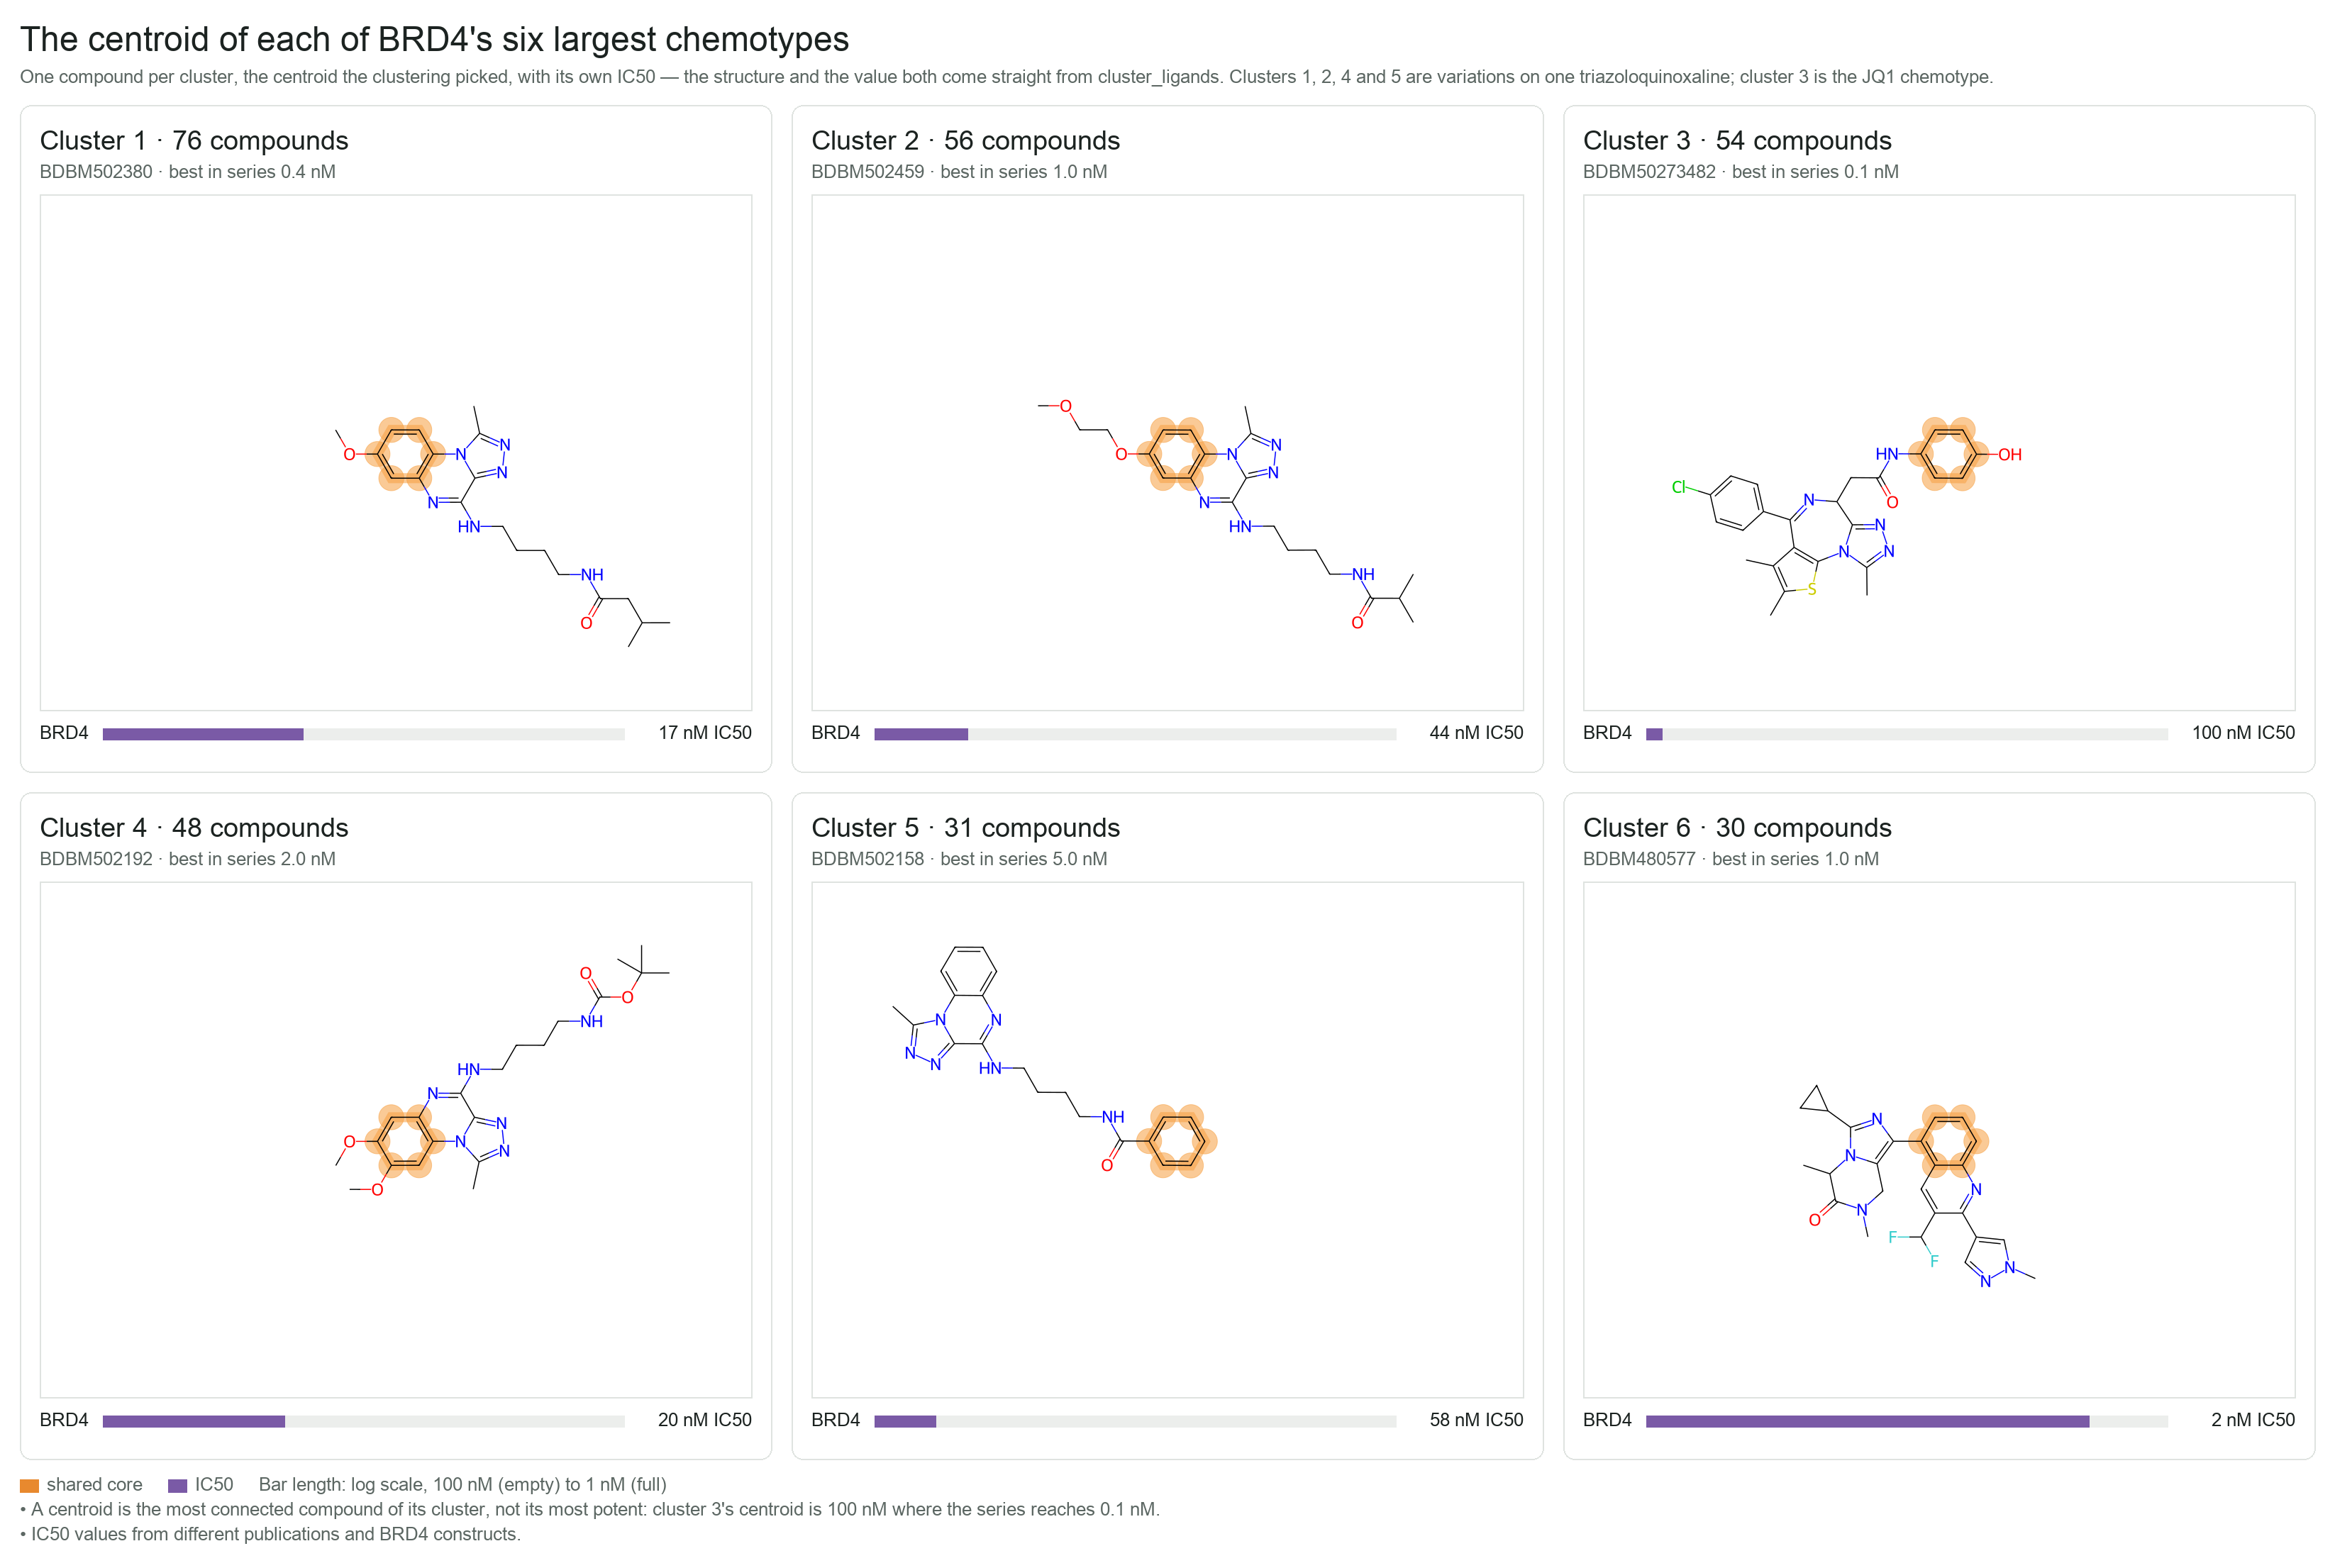

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': "The centroid of each of BRD4's six largest chemotypes",
    'compounds': [
        {
            'smiles': 'COc1ccc2c(c1)nc(NCCCCNC(=O)CC(C)C)c1nnc(C)n21',
            'title': 'Cluster 1 · 76 compounds',
            'subtitle': 'BDBM502380 · best in series 0.4 nM',
            'bars': [{'label': 'BRD4', 'value_nm': 17.0, 'type': 'IC50'}],
        },
        {
            'smiles': 'COCCOc1ccc2c(c1)nc(NCCCCNC(=O)C(C)C)c1nnc(C)n21',
            'title': 'Cluster 2 · 56 compounds',
            'subtitle': 'BDBM502459 · best in series 1.0 nM',
            'bars': [{'label': 'BRD4', 'value_nm': 44.0, 'type': 'IC50'}],
        },
        {
            'smiles': 'Cc1sc-2c(c1C)C(=NC(CC(=O)Nc1ccc(O)cc1)c1nnc(C)n-21)c1ccc(Cl)cc1 |c:8|',
            'title': 'Cluster 3 · 54 compounds',
            'subtitle': 'BDBM50273482 · best in series 0.1 nM',
            'bars': [{'label': 'BRD4', 'value_nm': 100.0, 'type': 'IC50'}],
        },
        {
            'smiles': 'COc1cc2nc(NCCCCNC(=O)OC(C)(C)C)c3nnc(C)n3c2cc1OC',
            'title': 'Cluster 4 · 48 compounds',
            'subtitle': 'BDBM502192 · best in series 2.0 nM',
            'bars': [{'label': 'BRD4', 'value_nm': 20.0, 'type': 'IC50'}],
        },
        {
            'smiles': 'Cc1nnc2c(NCCCCNC(=O)c3ccccc3)nc3ccccc3n12',
            'title': 'Cluster 5 · 31 compounds',
            'subtitle': 'BDBM502158 · best in series 5.0 nM',
            'bars': [{'label': 'BRD4', 'value_nm': 58.0, 'type': 'IC50'}],
        },
        {
            'smiles': 'CC1C(=O)N(C)Cc2c(nc(C3CC3)n12)-c1cccc2nc(-c3cnn(C)c3)c(cc12)C(F)F',
            'title': 'Cluster 6 · 30 compounds',
            'subtitle': 'BDBM480577 · best in series 1.0 nM',
            'bars': [{'label': 'BRD4', 'value_nm': 2.0, 'type': 'IC50'}],
        },
    ],
    'columns': 3,
    'description': 'One compound per cluster, the centroid the clustering picked, with its own IC50 — the structure and the value both come straight from cluster_ligands. Clusters 1, 2, 4 and 5 are variations on one triazoloquinoxaline; cluster 3 is the JQ1 chemotype.',
    'notes': [
        "A centroid is the most connected compound of its cluster, not its most potent: cluster 3's centroid is 100 nM where the series reaches 0.1 nM.",
        'IC50 values from different publications and BRD4 constructs.',
    ],
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

**Yes — scaffold keying splits these series apart.**

Over the same 2,814 compounds there are 1,258 distinct
Bemis-Murcko scaffolds against 826 clusters, so grouping by scaffold produces
1.5 times as many groups as clustering does.

The reason is visible inside a single cluster: cluster 4's 48 compounds carry
8 different Bemis-Murcko scaffolds between them, because the scaffold
includes the ring substitution pattern — a 7-methoxy and a 7,8-dimethoxy quinoxaline are two scaffolds
but one series to a chemist. Clustering on the fingerprint keeps them together; scaffold keying files
them separately and would make the series look 8 times less explored than
it is.

The two views answer different questions. Use `group_by_scaffold` to ask which exact ring system a
compound is built on; use `cluster_ligands` to ask how many distinct series exist and to pick one
representative from each, as in the figure — which draws the six centroids with the structures and
potencies the clustering itself returned.

Read those bars as typical, not best: a centroid is the compound with the most neighbours in its cluster,
so cluster 3's centroid sits at 100.0 nM while the series reaches
0.1 nM. Each panel names its cluster's best compound underneath.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 4 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.9, commit 5ea8c6253a4c012b3f3982669393dcdf831fca79, https://github.com/pwrose/mcp-bindingdb
- Analysis: How many distinct chemotypes hit BRD4, 2026-11-23, with claude-opus-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/pwrose/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```